### setup

In [1]:
!pwd

/Users/zagidull/Desktop/synosys/lina-s paper


In [2]:
%load_ext autoreload

In [3]:
%autoreload 2

In [4]:
import numpy as np
import pandas as pd
import os
import scipy.stats
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from mymodule import get_contigs_idx, rr_to_bpm, bpm_to_rr, get_mismatchBBI
import statsmodels.formula.api as smf
import statsmodels.api as sm
from systole.plots import plot_rr
from systole.detection import rr_artefacts
from systole.correction import correct_rr, correct_peaks
from systole.hrv import rmssd, all_domain
from systole.plots import plot_subspaces
# https://journals.sagepub.com/doi/full/10.1177/07487304251348516
# https://github.com/LegrandNico/systole

os.chdir('/Users/zagidull/Desktop/synosys/lina-s paper/')


In [5]:
df = pd.read_csv('data/SynoSys_27.02.2026-15.04.2026.csv/bbi-(enhanced).csv')
print(df.shape)
df.head()

(6576006, 17)


,User Id,User First Name,User Last Name,User Email,Team Names,Group Names,Calendar Date (Local),Start Time (Local),Time Zone (Local),Calendar Date (UTC),Start Time (UTC),Start Time (ms),Time Zone (s),BBI (ms),Gap Duration (ms),Status,BBI Type
0,69aa9a01c272d7436ea5db59,Paultest,NaN,3aa9b47e@nomail.local,NaN,SynoSys,2026-03-06,2026-03-06T10:24:12.000,100,2026-03-06,2026-03-06T09:24:12.000,1772789052000,3600,1007,NaN,LOW_CONFIDENCE,Enhanced BBI
1,69aa9a01c272d7436ea5db59,Paultest,NaN,3aa9b47e@nomail.local,NaN,SynoSys,2026-03-06,2026-03-06T10:24:13.508,100,2026-03-06,2026-03-06T09:24:13.508,1772789053508,3600,1507,NaN,LOW_CONFIDENCE,Enhanced BBI
2,69aa9a01c272d7436ea5db59,Paultest,NaN,3aa9b47e@nomail.local,NaN,SynoSys,2026-03-06,2026-03-06T10:24:14.131,100,2026-03-06,2026-03-06T09:24:14.131,1772789054131,3600,625,NaN,LOW_CONFIDENCE,Enhanced BBI
3,69aa9a01c272d7436ea5db59,Paultest,NaN,3aa9b47e@nomail.local,NaN,SynoSys,2026-03-06,2026-03-06T10:24:14.818,100,2026-03-06,2026-03-06T09:24:14.818,1772789054818,3600,687,NaN,LOW_CONFIDENCE,Enhanced BBI
4,69aa9a01c272d7436ea5db59,Paultest,NaN,3aa9b47e@nomail.local,NaN,SynoSys,2026-03-06,2026-03-06T10:24:15.474,100,2026-03-06,2026-03-06T09:24:15.474,1772789055474,3600,656,NaN,LOW_CONFIDENCE,Enhanced BBI


### Preprocess

In [6]:
assert any(df.isna())

print(df.isna().sum())

User Id                        0
User First Name                0
User Last Name           6576006
User Email                     0
Team Names               6576006
Group Names                    0
Calendar Date (Local)          0
Start Time (Local)             0
Time Zone (Local)              0
Calendar Date (UTC)            0
Start Time (UTC)               0
Start Time (ms)                0
Time Zone (s)                  0
BBI (ms)                       0
Gap Duration (ms)        6576006
Status                         0
BBI Type                       0
dtype: int64


In [7]:
df = df.dropna(axis='columns', inplace=False) 
print(df.isna().sum())

User Id                  0
User First Name          0
User Email               0
Group Names              0
Calendar Date (Local)    0
Start Time (Local)       0
Time Zone (Local)        0
Calendar Date (UTC)      0
Start Time (UTC)         0
Start Time (ms)          0
Time Zone (s)            0
BBI (ms)                 0
Status                   0
BBI Type                 0
dtype: int64


In [8]:
pd.DataFrame(map(lambda col: (col, df[col].nunique(), df[col].dtype ), df.columns))

# looks like these 'Group Names' and 'BBI Type' cols can be dropped. Lets check other columns next 

,0,1,2
0,User Id,3,object
1,User First Name,3,object
2,User Email,3,object
3,Group Names,1,object
4,Calendar Date (Local),41,object
5,Start Time (Local),6572400,object
6,Time Zone (Local),2,int64
7,Calendar Date (UTC),41,object
8,Start Time (UTC),6572400,object
9,Start Time (ms),6572400,int64


In [9]:
all(
    pd.to_datetime(df['Start Time (ms)'], unit='ms', utc=True) \
    + pd.to_timedelta(df['Time Zone (s)'], unit='s') \
    == pd.to_datetime(df['Start Time (Local)'], utc=True))

# looks like Start Time (ms) is in UTC, ie Start Time (ms)+ Time Zone (s)= Start Time (Local)

True

In [10]:
df = df.assign( timeLocal_ms = df['Start Time (ms)']+df['Time Zone (s)']*1000) # so lets transform 'Start Time (ms)' to local time (ms), and then drop all other time columns
df.head()

,User Id,User First Name,User Email,Group Names,Calendar Date (Local),Start Time (Local),Time Zone (Local),Calendar Date (UTC),Start Time (UTC),Start Time (ms),Time Zone (s),BBI (ms),Status,BBI Type,timeLocal_ms
0,69aa9a01c272d7436ea5db59,Paultest,3aa9b47e@nomail.local,SynoSys,2026-03-06,2026-03-06T10:24:12.000,100,2026-03-06,2026-03-06T09:24:12.000,1772789052000,3600,1007,LOW_CONFIDENCE,Enhanced BBI,1772792652000
1,69aa9a01c272d7436ea5db59,Paultest,3aa9b47e@nomail.local,SynoSys,2026-03-06,2026-03-06T10:24:13.508,100,2026-03-06,2026-03-06T09:24:13.508,1772789053508,3600,1507,LOW_CONFIDENCE,Enhanced BBI,1772792653508
2,69aa9a01c272d7436ea5db59,Paultest,3aa9b47e@nomail.local,SynoSys,2026-03-06,2026-03-06T10:24:14.131,100,2026-03-06,2026-03-06T09:24:14.131,1772789054131,3600,625,LOW_CONFIDENCE,Enhanced BBI,1772792654131
3,69aa9a01c272d7436ea5db59,Paultest,3aa9b47e@nomail.local,SynoSys,2026-03-06,2026-03-06T10:24:14.818,100,2026-03-06,2026-03-06T09:24:14.818,1772789054818,3600,687,LOW_CONFIDENCE,Enhanced BBI,1772792654818
4,69aa9a01c272d7436ea5db59,Paultest,3aa9b47e@nomail.local,SynoSys,2026-03-06,2026-03-06T10:24:15.474,100,2026-03-06,2026-03-06T09:24:15.474,1772789055474,3600,656,LOW_CONFIDENCE,Enhanced BBI,1772792655474


In [11]:
 # sanity check just for the first row
assert pd.Timestamp(1_772_789_052_000, unit='ms')+pd.Timedelta(3_600*1000, unit='ms') == pd.Timestamp(1_772_792_652_000, unit='ms')
assert pd.Timestamp(1_772_792_652_000, unit='ms') == pd.to_datetime(df['Start Time (Local)'][0], utc=False)
print('ok')

ok


In [12]:
cols_drop=['User First Name', 'User Email', 'Group Names', 'Calendar Date (Local)', 'Start Time (Local)', 'Start Time (UTC)', 'Time Zone (Local)', 'Calendar Date (UTC)', 'BBI Type', 'Start Time (ms)', 'Time Zone (s)']
df = df.drop(labels=cols_drop, axis='columns', inplace=False)
df.head()

,User Id,BBI (ms),Status,timeLocal_ms
0,69aa9a01c272d7436ea5db59,1007,LOW_CONFIDENCE,1772792652000
1,69aa9a01c272d7436ea5db59,1507,LOW_CONFIDENCE,1772792653508
2,69aa9a01c272d7436ea5db59,625,LOW_CONFIDENCE,1772792654131
3,69aa9a01c272d7436ea5db59,687,LOW_CONFIDENCE,1772792654818
4,69aa9a01c272d7436ea5db59,656,LOW_CONFIDENCE,1772792655474


In [13]:
# lets map user id to something simple, like 0-1-2

userid_map = dict(zip( list(df['User Id'].unique()), range(0, df['User Id'].nunique()))) # better than using set(), because sets are non-deterministic
df['User Id'] = df['User Id'].map(userid_map)


### Statistical EDA

In [14]:
# how long measurements were collected for, stratify by User Id

df.groupby('User Id')['timeLocal_ms'].agg(lambda x: pd.to_timedelta( max(x)-min(x), unit='ms' ))

User Id
0    9 days 21:15:23.631000
1   36 days 11:00:11.940000
2   37 days 05:47:39.562000
Name: timeLocal_ms, dtype: timedelta64[ns]

In [15]:
# look at users

df.groupby('User Id')['BBI (ms)']\
    .agg(['mean','median','std','count']).round(0) 

# so id=0 has ~same mean&median
# 1 and 2 seem to skew to the right (median < mean), ie probably high-val outliers
# all have roughly equal std

,mean,median,std,count
User Id,,,,
0,860.0,859.0,246.0,566417
1,866.0,825.0,250.0,2701824
2,815.0,763.0,245.0,3307765


In [16]:
# look at status

df.groupby('Status')['BBI (ms)']\
    .agg(['mean','median' ,'std', 'count']).round(0)

# low-confidence scores have a much higher std than high confidence, and also right-skewed

,mean,median,std,count
Status,,,,
HIGH_CONFIDENCE,919.0,905.0,205.0,2914190
LOW_CONFIDENCE,777.0,719.0,261.0,3661816


In [17]:
# look at users&confidence,
# calculate min/max+moments,
# compare with ref normal distributions
# NO CLIPPING

ref_norm = scipy.stats.norm.rvs(loc=df['BBI (ms)'].mean(), 
                                scale=df['BBI (ms)'].std(), 
                                size=df.shape[0],random_state=1)
f=lambda v: [np.mean(v), 
             np.median(v), 
             np.mean(v)-np.median(v),
             np.std(v), 
             scipy.stats.skew(v), 
             scipy.stats.kurtosis(v)]

# in stratified (Status) data

# in stratified (Status+User) data
gr = df.groupby(['Status', 'User Id'])['BBI (ms)']\
    .agg(['mean', 'median', lambda x: np.mean(x)-np.median(x) , 'std', 'skew', pd.Series.kurt])

for status in ['HIGH_CONFIDENCE', 'LOW_CONFIDENCE']:
    gr.loc[(status,'all'), :] = f(df.loc[df['Status']==status, 'BBI (ms)'])
gr.loc[('HIGH+LOW','all'), :] = f(df['BBI (ms)']) # all data
gr.loc[('HIGH+LOW','ref gaussian'), :] = f(ref_norm) # ref dist all data

gr = gr.sort_index(inplace=False)
gr.columns=['mean', 'median', 'mean-median', 'std', 'skew', 'kurt']

gr.style.background_gradient(subset=[ 'mean-median' ,'std','skew','kurt'], cmap='coolwarm').format({k:'{:.0f}' for k in gr.columns})

### Visual EDA

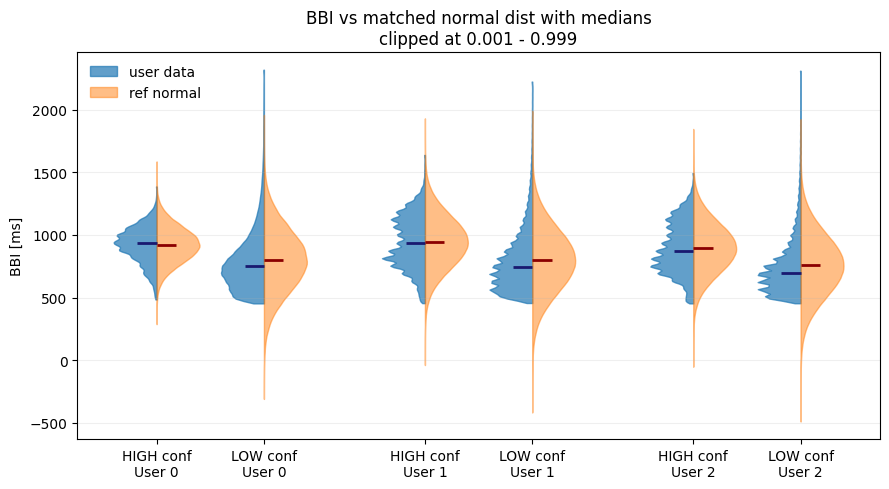

In [18]:
# compare BBI for each user with a reference normal dist (identical mean and std)
q=0.999

fig, ax = plt.subplots(figsize=(9, 5))

labels = []
positions = []
pos = 1

for user in sorted(df['User Id'].unique()):
    for status in sorted(df['Status'].unique()):
        # user data
        s = df.loc[(df['User Id'] == user) & (df['Status'] == status), 'BBI (ms)']
        u=s.quantile(q)
        l=s.quantile(1-q)
        s=np.clip(s, a_min=l, a_max=u)

        # ref dist. we clip first and then create a reference dist
        normal_ref = scipy.stats.norm.rvs(loc=s.mean(), scale=s.std(), size=len(s), random_state=1)

        v_actual = ax.violinplot([s], positions=[pos], widths=0.8, showextrema=False)
        v_normal = ax.violinplot([normal_ref], positions=[pos], widths=0.8, showextrema=False)

        # left is clipped BBI distribution
        body_actual = v_actual['bodies'][0]
        verts = body_actual.get_paths()[0].vertices
        verts[:, 0] = np.minimum(verts[:, 0], pos)
        body_actual.set_facecolor('tab:blue')
        body_actual.set_edgecolor('tab:blue')
        body_actual.set_alpha(0.7)

        # right is matched normal
        body_normal = v_normal['bodies'][0]
        verts = body_normal.get_paths()[0].vertices
        verts[:, 0] = np.maximum(verts[:, 0], pos)
        body_normal.set_facecolor('tab:orange')
        body_normal.set_edgecolor('tab:orange')
        body_normal.set_alpha(0.5)

        # median lines
        med_actual = np.median(s)
        med_normal = np.median(normal_ref)
        ax.hlines(med_actual, pos - 0.18, pos, color='midnightblue', lw=2)
        ax.hlines(med_normal, pos, pos + 0.18, color='darkred', lw=2)

        labels.append(f"{status.split('_')[0]} conf\nUser {user}")
        positions.append(pos)
        pos += 1

    pos += 0.5

ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_ylabel('BBI [ms]')
ax.set_title(f'BBI vs matched normal dist with medians\nclipped at {round(1-q, 4)} - {q}')
ax.grid(axis='y', alpha=0.2)

legend_handles = [
    Patch(facecolor='tab:blue', edgecolor='tab:blue', alpha=0.7, label='user data'),
    Patch(facecolor='tab:orange', edgecolor='tab:orange', alpha=0.5, label='ref normal'),
]
ax.legend(handles=legend_handles, frameon=False)

plt.tight_layout()
plt.show()


Text(0, 0.5, 'BBI [ms]')

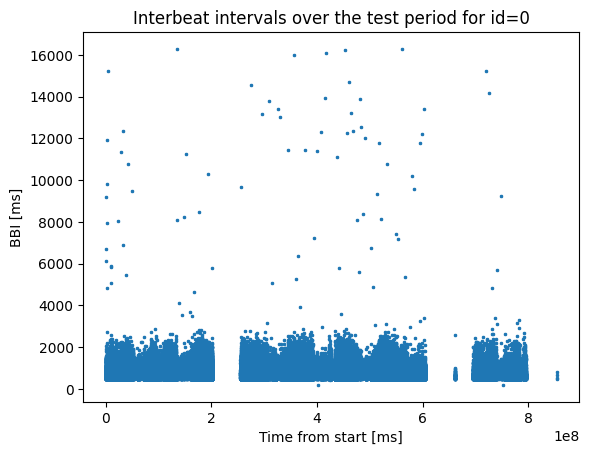

In [19]:
# lets look at a single user and show their measurements, x-axis is ms from the start of the analysis
user=0

temp=df.loc[df['User Id']==user,:]
x=temp['timeLocal_ms']-temp['timeLocal_ms'].min() 
y=temp['BBI (ms)']

fig,ax=plt.subplots()
ax.scatter(x=x, y=y, marker='x', s=3)
ax.set_title(f'Interbeat intervals over the test period for id={user}')
ax.set_xlabel('Time from start [ms]')
ax.set_ylabel('BBI [ms]') 

# clearly ms is a shitty resolution + there are a few outliers that make BBI values squished

(450.0, 1250.0)

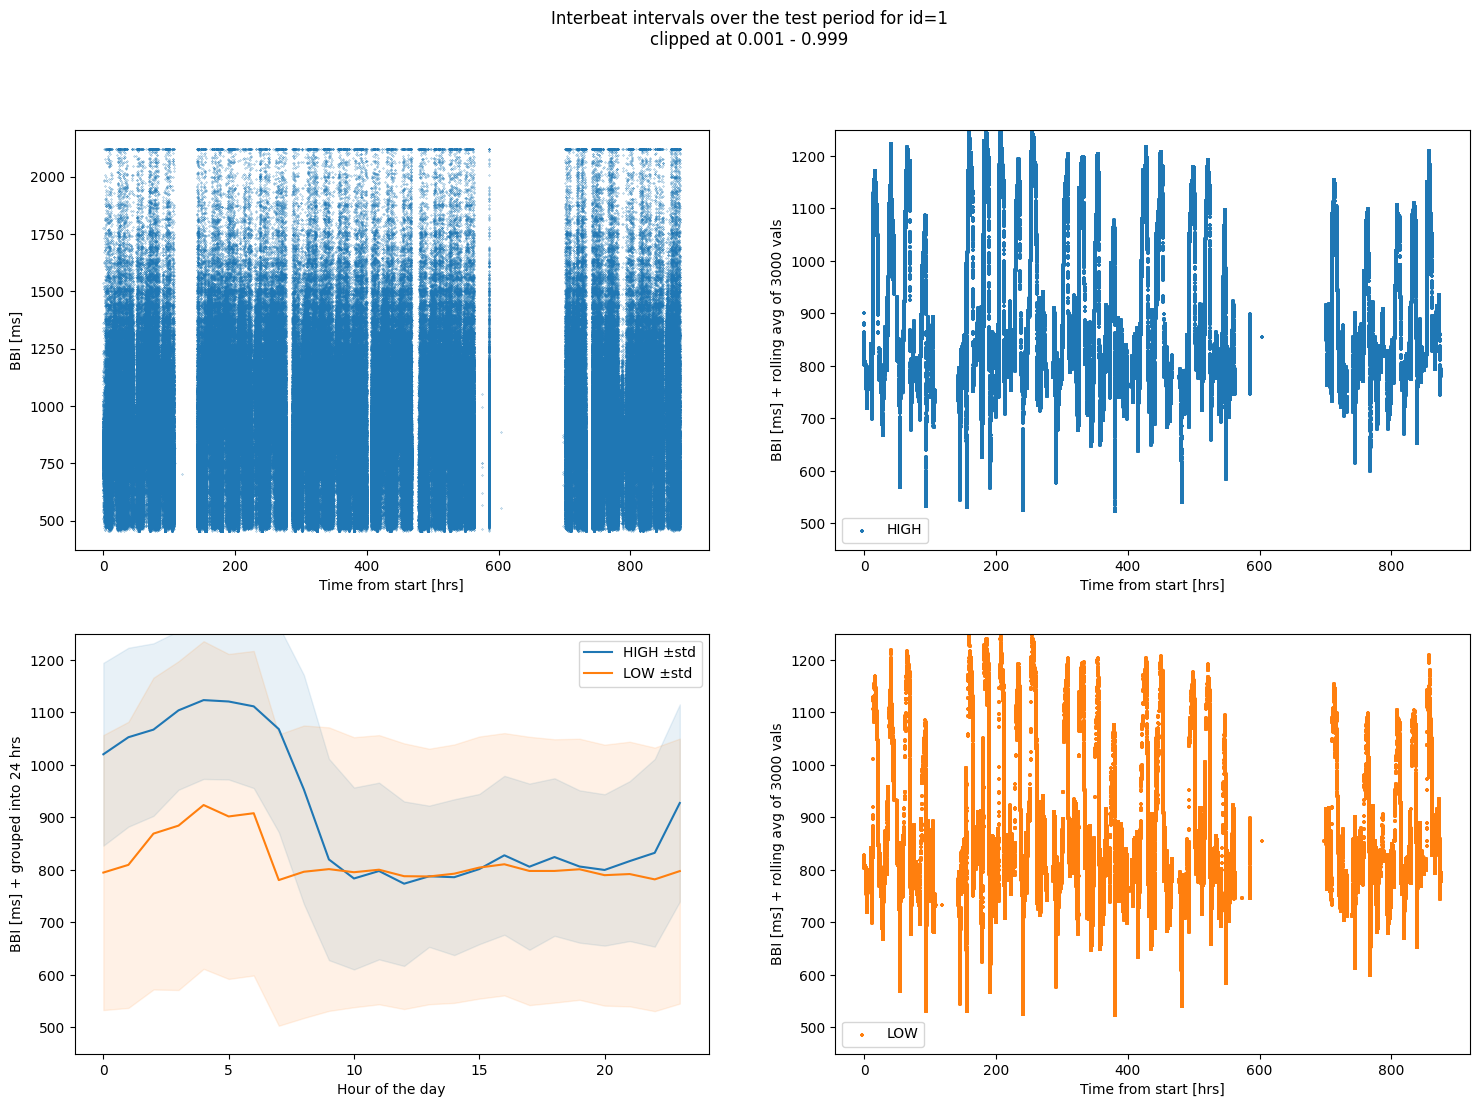

In [20]:
# winsorize, moving average, and groupby time of day for a single user
user=1
q=0.999 # very modest 
w=3_000 # do rolling average over w window

fig,ax=plt.subplots(nrows=2, ncols=2, figsize=(18,12))
fig.suptitle(f'Interbeat intervals over the test period for id={user}\nclipped at {round(1-q, 4)} - {q}')
temp=df.loc[df['User Id']==user,:]

# Plot 1. clipped, no other processing
x=pd.to_timedelta(temp['timeLocal_ms']-temp['timeLocal_ms'].min(), unit='ms').dt.total_seconds() /3600 # let's change x to better unit, eg hours?
q_h=temp['BBI (ms)'].quantile(q) 
q_l=temp['BBI (ms)'].quantile(1-q) 
y=temp['BBI (ms)'].clip(upper=q_h, lower=q_l)
ax[0,0].scatter(x=x, y=y, s=.05)
ax[0,0].set_xlabel('Time from start [hrs]')
ax[0,0].set_ylabel('BBI [ms]')

# Plots 2&4. clipped + moving average
y=y.rolling(window=w, min_periods=1).mean()
for status in ['HIGH_CONFIDENCE', 'LOW_CONFIDENCE']:
    mask=temp['Status'] == status
    if status=='HIGH_CONFIDENCE': 
        a=ax[0,1] 
        c='tab:blue'
    else: 
        a=ax[1,1]
        c='tab:orange'
    a.scatter(x=x[mask], y=y[mask], label=status.split('_')[0], marker='+', s=5, c=c)
    a.legend()
    a.set_xlabel('Time from start [hrs]')
    a.set_ylabel(f'BBI [ms] + rolling avg of {w} vals') 
    a.set_ylim((450,1250))
    

# Plot 3. groupby [hour_of_day, status], then clip. Add CIs
hr=pd.to_datetime(temp['timeLocal_ms'], unit='ms').dt.hour
y=temp.groupby([hr, 'Status'])['BBI (ms)'].agg(
    lambda s: np.mean(s.clip(upper=q_h, lower=q_l))
    ).unstack('Status')
y_int=temp.groupby([hr, 'Status'])['BBI (ms)'].agg(
    lambda s: np.std(s.clip(upper=q_h, lower=q_l))
    ).unstack('Status')

for status in y.columns:
    if status=='HIGH_CONFIDENCE': c='tab:blue'
    else: c='tab:orange'
    ax[1,0].plot(y.index, y[status], label=status.split('_')[0]+' ±std')
    ax[1,0].fill_between(y.index, y[status]-y_int[status], y[status]+y_int[status], color=c, alpha=0.1)
ax[1,0].legend()    
ax[1,0].set_ylabel('BBI [ms] + grouped into 24 hrs') 
ax[1,0].set_xlabel('Hour of the day')
ax[1,0].set_ylim((450,1250))


Text(0.5, 1.0, 'BBI ±std all users')

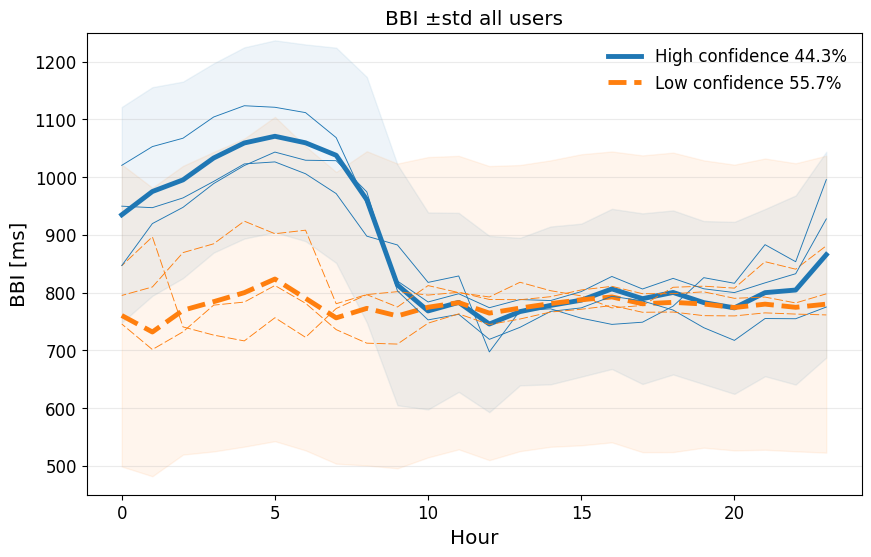

In [21]:
# lets do all users
q=0.999
fig,ax=plt.subplots(nrows=1, ncols=1, figsize=(10,6))
hr=pd.to_datetime(df['timeLocal_ms'], unit='ms').dt.hour 
counts=round((100*df.groupby('Status').size()/len(df)), 1).to_dict() #in percent

y=df.groupby([hr, 'Status'])['BBI (ms)']\
    .agg(lambda s: np.mean(s.clip(upper=s.quantile(q), lower=s.quantile(1-q)))).unstack('Status')
y_int=df.groupby([hr, 'Status'])['BBI (ms)']\
    .agg(lambda s: np.std(s.clip(upper=s.quantile(q), lower=s.quantile(1-q)))).unstack('Status')

ax.plot(y.index, y['HIGH_CONFIDENCE'], linewidth=3.5, linestyle='solid', c='tab:blue', label=f'High confidence {counts.get('HIGH_CONFIDENCE')}%')
ax.plot(y.index, y['LOW_CONFIDENCE'], linewidth=3.5, linestyle='dashed', c='tab:orange', label=f'Low confidence {counts.get('LOW_CONFIDENCE')}%')
ax.fill_between(y.index, y['HIGH_CONFIDENCE']-y_int['HIGH_CONFIDENCE'], y['HIGH_CONFIDENCE']+y_int['HIGH_CONFIDENCE'], color='tab:blue', alpha=0.075)
ax.fill_between(y.index, y['LOW_CONFIDENCE']-y_int['LOW_CONFIDENCE'], y['LOW_CONFIDENCE']+y_int['LOW_CONFIDENCE'], color='tab:orange', alpha=0.075)

# plot individual user lines
for user in df['User Id'].drop_duplicates():
    temp=df.loc[df['User Id']==user, :]
    q_h=temp['BBI (ms)'].quantile(q)
    q_l=temp['BBI (ms)'].quantile(1-q)

    y=temp.groupby([hr[temp.index], 'Status'])['BBI (ms)']\
        .agg(lambda s: np.mean(s.clip(upper=q_h, lower=q_l))).unstack('Status')
    for status in y.columns:
        if status=='HIGH_CONFIDENCE': 
            linestyle='solid'
            c='tab:blue'
        else: 
            linestyle=(5, (10, 3))
            c='tab:orange'
        ax.plot(y.index, y[status], linewidth=0.65, ls=linestyle, c=c)
ax.grid(axis='y', alpha=0.25)
ax.tick_params(axis='both', labelsize='large')
ax.legend(frameon=False, fontsize='large')    
ax.set_ylabel('BBI [ms]', fontsize='x-large') 
ax.set_xlabel('Hour', fontsize='x-large') 
ax.set_ylim((450,1250))
ax.set_title(f'BBI ±std all users', fontsize='x-large')


Text(0.5, 1.0, 'Signal confidence all users')

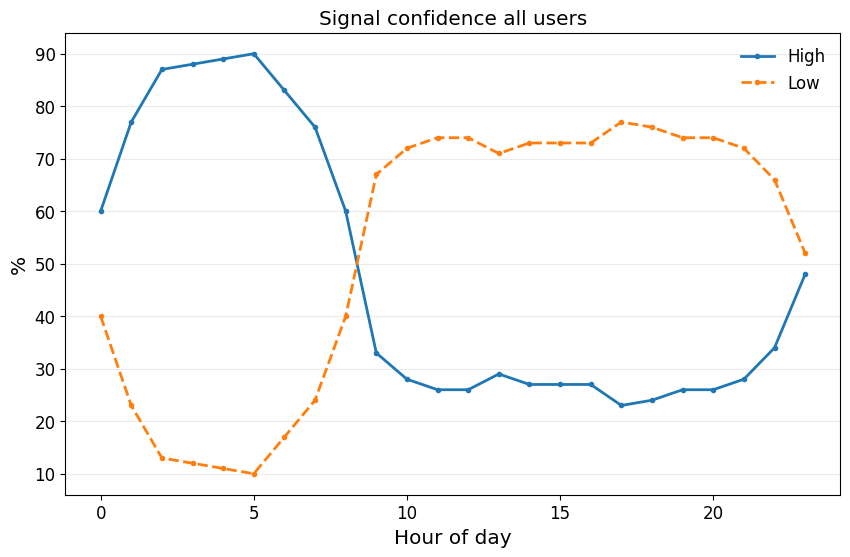

In [22]:
# % vals by STATUS
fig,ax=plt.subplots(nrows=1, ncols=1, figsize=(10,6))
hr=pd.to_datetime(df['timeLocal_ms'], unit='ms').dt.hour 
gr=df.groupby([hr, 'Status'])['BBI (ms)'].size().unstack('Status')\
    .apply(lambda col: 100*round(col/col.sum(), 2), axis='columns')
gr.index.name='hour of day'


ax.plot(gr.index, gr['HIGH_CONFIDENCE'], marker='.' , lw=2, ls='solid', label='High', c='tab:blue')
ax.plot(gr.index, gr['LOW_CONFIDENCE'], marker='.', lw=2, ls='dashed', label='Low', c='tab:orange')
ax.legend(frameon=False, fontsize='large')
ax.tick_params(axis='both', labelsize='large')
ax.grid(axis='y', alpha=0.25)
ax.set_ylabel('%', fontsize='x-large') 
ax.set_xlabel('Hour of day', fontsize='x-large') 
ax.set_title(f'Signal confidence all users', fontsize='x-large')
#plt.savefig('low_vs_high fraction 27.02.2026-15.04.2026 data.png')


### random BBI exploration

In [23]:
df.head()

,User Id,BBI (ms),Status,timeLocal_ms
0,0,1007,LOW_CONFIDENCE,1772792652000
1,0,1507,LOW_CONFIDENCE,1772792653508
2,0,625,LOW_CONFIDENCE,1772792654131
3,0,687,LOW_CONFIDENCE,1772792654818
4,0,656,LOW_CONFIDENCE,1772792655474


In [24]:
# based on timestamps 178.804seconds passed between 0 and 200th BBI measurement
print((df.iloc[199, 3] - df.iloc[0, 3])/1000)

# based on summing the intervals 143 seconds passed (+199ms for off-by-one)
print(df.iloc[1:200, 1].sum()/1000)

#what gives? mb it is only the case for low confidence

178.804
143.134


In [25]:
# pick high confidence for user 0
a=df[df['User Id']==0]['Status'].map({'LOW_CONFIDENCE':0, 'HIGH_CONFIDENCE':1})

start,end,lens = get_contigs_idx(ar_input=a, top_n=2, get_high=True)

In [26]:
temp = df.iloc[start[0]:end[0], :] # extend iloc index +-1 for sanity echecking
assert temp.shape[0]==lens[0]
temp.head()

,User Id,BBI (ms),Status,timeLocal_ms
373474,0,1046,HIGH_CONFIDENCE,1773283036164
373475,0,1023,HIGH_CONFIDENCE,1773283037187
373476,0,1015,HIGH_CONFIDENCE,1773283038202
373477,0,968,HIGH_CONFIDENCE,1773283039170
373478,0,1031,HIGH_CONFIDENCE,1773283040201


In [27]:
temp.tail()

,User Id,BBI (ms),Status,timeLocal_ms
374792,0,851,HIGH_CONFIDENCE,1773284278610
374793,0,843,HIGH_CONFIDENCE,1773284279453
374794,0,867,HIGH_CONFIDENCE,1773284280328
374795,0,898,HIGH_CONFIDENCE,1773284281226
374796,0,835,HIGH_CONFIDENCE,1773284282061


In [28]:
1773284280328-1773284279453

875

In [29]:
# that looks much better for high confidence values, but still there are some difference
print( sum(np.ediff1d(temp['timeLocal_ms']) != temp['BBI (ms)'].iloc[1:]) ) # 88 vals are different
print( sum(np.ediff1d(temp['timeLocal_ms']) -  temp['BBI (ms)'].iloc[1:]) ) # errors sum up to 626 ms, probably not a big deal

88
626


In [30]:
# where are mistake?
mistakes = np.where( (np.ediff1d(temp['timeLocal_ms']) -  temp['BBI (ms)'].iloc[1:])!=0 )[0]+1 #idx of mistakes
print(mistakes[2])
temp.reset_index(drop=True).iloc[44:46] # 1773283065007-1773283064125=968, but BBI is 960

45


,User Id,BBI (ms),Status,timeLocal_ms
44,0,953,HIGH_CONFIDENCE,1773283078024
45,0,960,HIGH_CONFIDENCE,1773283078992


### explore high vs low conf contigs statistics for users


In [31]:
user=2
shortest_contig=100

In [32]:
# high conf, user=2

use_fast=True

# high conf
temp=get_mismatchBBI(df[df['User Id']==user], top_n=999999, shortest_contig=shortest_contig, get_high=True, return_corr=False, use_fast=use_fast)
g=pd.to_datetime(temp['time'], format="%H:%M").dt.hour # grouper
temp_h = temp.groupby(g).agg(
    len_contig=('len_contig', 'mean'),
    mismatches_per_contig=('mismatches_per_contig', 'mean'),
    sum_errors_ms=('sum_errors_ms', 'sum'),
    n_contigs=('len_contig', 'size'),
)
temp_h['error_per_contig_seconds']=temp_h['sum_errors_ms']/(1000*temp_h['n_contigs'])

# low conf
temp1=get_mismatchBBI(df[df['User Id']==user], top_n=999999, shortest_contig=shortest_contig, get_high=False, return_corr=False, use_fast=use_fast)
g1=pd.to_datetime(temp1['time'], format="%H:%M").dt.hour # grouper
temp_l = temp1.groupby(g1).agg(
    len_contig=('len_contig', 'mean'),
    mismatches_per_contig=('mismatches_per_contig', 'mean'),
    sum_errors_ms=('sum_errors_ms', 'sum'),
    n_contigs=('len_contig', 'size'),
)
temp_l['error_per_contig_seconds']=temp_l['sum_errors_ms']/(1000*temp_l['n_contigs'])

cols=['n_contigs', 'error_per_contig_seconds', 'len_contig'] # cols to pick for display
temp_hl=pd.concat([temp_h[cols].add_suffix(" HIGH"), temp_l[cols].add_suffix(" LOW")], axis=1)

temp_hl = temp_hl[['n_contigs LOW', 'n_contigs HIGH', 'len_contig LOW', 'len_contig HIGH', 'error_per_contig_seconds LOW', 'error_per_contig_seconds HIGH' ]]
shared1=['n_contigs LOW', 'n_contigs HIGH']
shared2=['len_contig LOW', 'len_contig HIGH']
shared3=['error_per_contig_seconds LOW', 'error_per_contig_seconds HIGH']
tmp=(temp_hl.style\
    .background_gradient(subset=shared1, cmap='coolwarm', vmin=temp_hl[shared1].min().min(), vmax=temp_hl[shared1].max().max())
    .background_gradient(subset=shared2, cmap='PRGn', vmin=temp_hl[shared2].min().min(), vmax=temp_hl[shared2].max().max())
    .background_gradient(subset=shared3, cmap='coolwarm', vmin=temp_hl[shared3].min().min(), vmax=temp_hl[shared3].max().max())
    )
tmp.format({k:'{:.2f}' if k in shared3 else '{:.0f}' for k in tmp.columns})

,n_contigs LOW,n_contigs HIGH,len_contig LOW,len_contig HIGH,error_per_contig_seconds LOW,error_per_contig_seconds HIGH
time,,,,,,
0,135,69,240,222,4.62,1.43
1,44,269,624,208,5744.92,13.43
2,9,311,973,220,0.13,1.52
3,3,296,1233,234,0.67,0.05
4,9,281,799,207,936.94,0.05
5,6,265,477,217,0.16,0.06
6,16,249,1034,201,0.24,0.05
7,16,236,990,199,11779.09,0.07
8,28,242,345,193,1050.79,0.06


In [33]:
# all users
holder=[]
for user in sorted(df['User Id'].unique()):
    # high conf
    temp=get_mismatchBBI(df[df['User Id']==user], top_n=999999, shortest_contig=shortest_contig, get_high=True, return_corr=False, use_fast=use_fast)
    g=pd.to_datetime(temp['time'], format="%H:%M").dt.hour # grouper
    temp_h = temp.groupby(g).agg(
        len_contig=('len_contig', 'mean'),
        mismatches_per_contig=('mismatches_per_contig', 'mean'),
        sum_errors_ms=('sum_errors_ms', 'sum'),
        n_contigs=('len_contig', 'size'),
    )
    temp_h['error_per_contig_seconds']=temp_h['sum_errors_ms']/(1000*temp_h['n_contigs'])

    # low conf
    temp1=get_mismatchBBI(df[df['User Id']==user], top_n=999999, shortest_contig=shortest_contig, get_high=False, return_corr=False, use_fast=use_fast)
    g1=pd.to_datetime(temp1['time'], format="%H:%M").dt.hour # grouper
    temp_l = temp1.groupby(g1).agg(
        len_contig=('len_contig', 'mean'),
        mismatches_per_contig=('mismatches_per_contig', 'mean'),
        sum_errors_ms=('sum_errors_ms', 'sum'),
        n_contigs=('len_contig', 'size'),
    )
    temp_l['error_per_contig_seconds']=temp_l['sum_errors_ms']/(1000*temp_l['n_contigs'])

    cols=['n_contigs', 'error_per_contig_seconds', 'len_contig'] # cols to pick for display
    temp_hl=pd.concat([temp_h[cols].add_suffix(" HIGH"), temp_l[cols].add_suffix(" LOW")], axis=1)

    #temp_hl=temp_hl.fillna(0)
    holder.append(temp_hl)

temp_all=pd.concat(holder).groupby(level=0).mean() # averaging
temp_all = temp_all[['n_contigs LOW', 'n_contigs HIGH', 'len_contig LOW', 'len_contig HIGH', 'error_per_contig_seconds LOW', 'error_per_contig_seconds HIGH' ]]
shared1=['n_contigs LOW', 'n_contigs HIGH']
shared2=['len_contig LOW', 'len_contig HIGH']
shared3=['error_per_contig_seconds LOW', 'error_per_contig_seconds HIGH']
tmp=(temp_all.style\
    .background_gradient(subset=shared1, cmap='coolwarm', vmin=temp_all[shared1].min().min(), vmax=temp_all[shared1].max().max())
    .background_gradient(subset=shared2, cmap='PRGn', vmin=temp_all[shared2].min().min(), vmax=temp_all[shared2].max().max())
    .background_gradient(subset=shared3, cmap='coolwarm', vmin=temp_all[shared3].min().min(), vmax=temp_all[shared3].max().max())
    )
tmp.format({k:'{:.2f}' if k in shared3 else '{:.0f}' for k in tmp.columns})


,n_contigs LOW,n_contigs HIGH,len_contig LOW,len_contig HIGH,error_per_contig_seconds LOW,error_per_contig_seconds HIGH
time,,,,,,
0,51,89,222,304,774.92,0.56
1,20,178,316,262,2043.24,4.55
2,9,183,914,299,2980.32,0.58
3,4,184,887,275,46.06,0.20
4,4,176,926,262,313.43,0.09
5,4,182,1189,237,1.06,0.08
6,7,174,863,224,1.44,0.07
7,11,153,747,217,4188.61,0.07
8,41,109,259,189,442.28,0.07


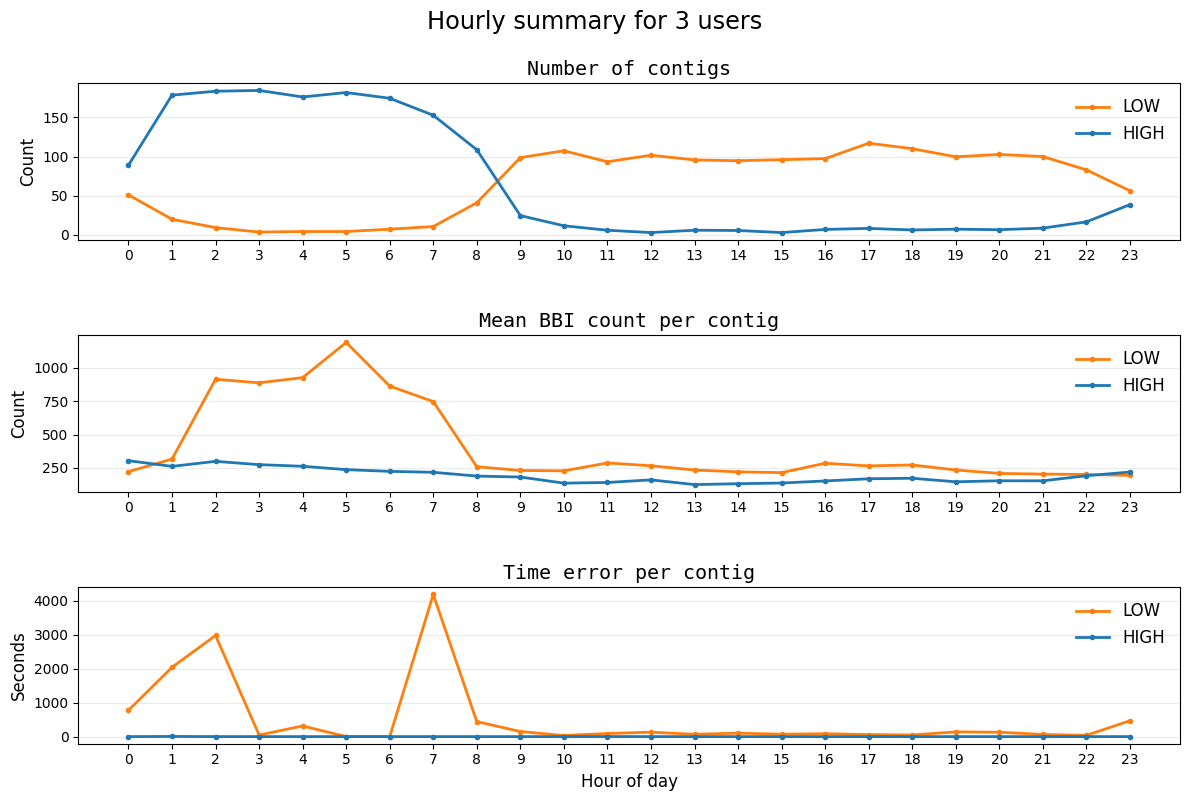

In [34]:
plot_df = temp_all.sort_index().copy()

fig, ax = plt.subplots(nrows=3, figsize=(12, 8), sharex=False)

pairs = [
    ('n_contigs LOW', 'n_contigs HIGH', 'Number of contigs', 'Count'),
    ('len_contig LOW', 'len_contig HIGH', 'Mean BBI count per contig', 'Count'),
    ('error_per_contig_seconds LOW', 'error_per_contig_seconds HIGH', 'Time error per contig', 'Seconds'),
]

colors = {'LOW': 'tab:orange', 'HIGH': 'tab:blue'}

for a, (low_col, high_col, title, ylabel) in zip(ax, pairs):
    a.plot(plot_df.index, plot_df[low_col], marker='.', lw=2, color=colors['LOW'], label='LOW')
    a.plot(plot_df.index, plot_df[high_col], marker='.', lw=2, color=colors['HIGH'], label='HIGH')
    a.set_title(title, fontsize='x-large', fontfamily='monospace')
    a.set_ylabel(ylabel, fontsize='large')
    a.tick_params(axis='both', labelsize='medium')
    a.grid(axis='y', alpha=0.25)
    a.legend(frameon=False, fontsize='large')

    a.set_xticks(range(24))

ax[-1].set_xlabel('Hour of day', fontsize='large')

fig.suptitle('Hourly summary for 3 users', fontsize='xx-large', y=0.995)
plt.tight_layout(h_pad=3.5)


### modelling Confidence status

In [35]:
def timestamp_bbi_stats(g: pd.DataFrame) -> pd.Series:
    if len(g) < 2:
        return pd.Series({
            "n_mismatch": 0,
            "mismatch_frac": np.nan,
            "sum_errors_ms": np.nan,
            "mean_error_ms": np.nan,
        })

    dt = np.ediff1d(g["timeLocal_ms"])
    bbi = g["BBI (ms)"].iloc[1:].to_numpy()
    abs_err = np.abs(dt - bbi)
    mismatch = dt != bbi

    return pd.Series({
        "n_mismatch": int(mismatch.sum()),
        "mismatch_frac": mismatch.mean(),
        "sum_errors_ms": abs_err.sum(),
        "mean_error_ms": abs_err.mean(),
    })

In [36]:
time_interval='30min'
user=1

temp=df.loc[df['User Id']==user, :]
temp=temp.assign(dt=pd.to_datetime(temp['timeLocal_ms'], unit='ms'))
temp=temp.set_index('dt')

start = temp.index.min().floor(time_interval)
end = temp.index.max().ceil(time_interval)
new_idx = pd.date_range(start, end, freq=time_interval, inclusive='left')

win1=temp.groupby(pd.Grouper(freq=time_interval))\
    .agg(
        n=('BBI (ms)', 'size'),
        n_high=('Status', lambda s: int(sum(s=='HIGH_CONFIDENCE'))),
        n_low=('Status', lambda s: int(sum(s=='LOW_CONFIDENCE'))),
        median=('BBI (ms)', 'median'),
        mean=('BBI (ms)', 'mean'),
        qd=('BBI (ms)', lambda s: (s.quantile(0.75)-s.quantile(0.25))/2),
        skew=('BBI (ms)', 'skew'),
        std=('BBI (ms)', 'std'),
        sem=('BBI (ms)', 'sem'),
        top5=('BBI (ms)', lambda s: s.quantile(0.95)),
        rmssd=('BBI (ms)', lambda s: np.sqrt(np.mean(np.ediff1d(s) ** 2))),
        switch_rate=('Status', lambda s: np.mean(s.ne(s.shift()).iloc[1:])),
        )

win2=temp.groupby(pd.Grouper(freq=time_interval)).apply(timestamp_bbi_stats)

win1=win1.reindex(new_idx)
win2=win2.reindex(new_idx)

# fill missing with means
#d1=win1.apply(np.nanmean, axis='rows').to_dict()
#d2=win2.apply(np.nanmean, axis='rows').to_dict()
#win1=win1.fillna(d1)
#win2=win2.fillna(d2)

# combine 
win=win1.join(win2)
win['sin(min)']= np.sin(2*np.pi* (win.index.hour*60 + win.index.minute) /1440)
win['cos(min)']= np.cos(2*np.pi* (win.index.hour*60 + win.index.minute) /1440)

# cannot have 0 n_high/n_low because div by 0
to_drop=win[(win['n'])==0].index
print(len(to_drop) / len(win)) 
win = win.drop(index=to_drop)
win = win.dropna(axis='rows')


/Users/zagidull/miniconda3/envs/py313/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/zagidull/miniconda3/envs/py313/lib/python3.13/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


0.2501427755568247


In [37]:
# normalise cols to 0-mean, 1-std
# fit 3 log-regs: ~ time, ~ rmssd, ~ time + rmssd

f=lambda x: (x - x.mean()) / x.std()
cols = ['sin(min)', 'cos(min)', 'rmssd']
win.loc[:,cols] = win[cols].apply(f)

win=win.assign(frac=win.n_high/win.n)
m0 = smf.glm(
    "frac ~ Q('sin(min)')+Q('cos(min)')",
    data=win,
    family=sm.families.Binomial(),
).fit()

m1 = smf.glm(
    "frac ~ rmssd",
    data=win,
    family=sm.families.Binomial(),
).fit()

m2 = smf.glm(
    "frac ~ Q('sin(min)')+Q('cos(min)')+rmssd",
    data=win,
    family=sm.families.Binomial(),
).fit()

print(f'RMSSD vs Time + RMSSD LR={2 * round(m2.llf - m1.llf, 2)}')
print(f'Time vs Time + RMSSD LR={2 * round(m2.llf - m0.llf, 2)}')
print(f'{round(m1.pearson_chi2 / m1.df_resid, 2)} dispersion should ~1, so thats probably a misspeced dist')

RMSSD vs Time + RMSSD LR=14.34
Time vs Time + RMSSD LR=279.02
0.1 dispersion should ~1, so thats probably a misspeced dist


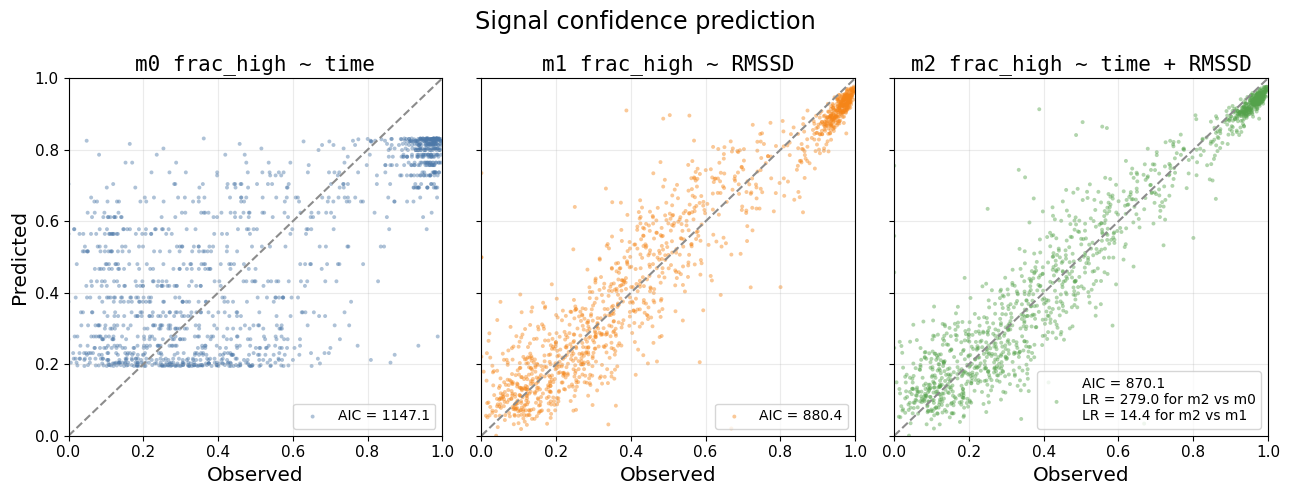

In [38]:
fig,ax=plt.subplots(ncols=3, figsize=(13,5), sharey=True, sharex=True)

specs = [
    (ax[0], m0.predict(), m0.aic, 'm0 frac_high ~ time', '#4c78a8'),
    (ax[1], m1.predict(), m1.aic, 'm1 frac_high ~ RMSSD', '#f58518'),
    (ax[2], m2.predict(), m2.aic, 'm2 frac_high ~ time + RMSSD', '#54a24b'),
]

for i, (a, pred, aic, title, color) in enumerate(specs):
    if i==2: 
        label=f'AIC = {aic:.1f}\nLR = {2*round(m2.llf-m0.llf,1)} for m2 vs m0\nLR = {2*round(m2.llf-m1.llf,1)} for m2 vs m1'
    else:
        label=f'AIC = {aic:.1f}'
    a.scatter(win['frac'], pred, s=8, alpha=0.45, color=color, edgecolor='none', label=label)
    a.axline((0,0), slope=1, color='0.55', lw=1.5, ls='--')
    a.set_title(title, fontsize=15, fontfamily='monospace')
    a.tick_params(axis='both', labelsize=11)
    a.grid(alpha=0.25)
    a.legend(frameon=True, loc='lower right', labelspacing=1.2)
    a.set_xlim((0,1))
    a.set_ylim((0,1))

ax[0].set_ylabel("Predicted", fontsize='x-large')
ax[0].set_xlabel("Observed", fontsize='x-large')
ax[1].set_xlabel("Observed", fontsize='x-large')
ax[2].set_xlabel("Observed", fontsize='x-large')

fig.suptitle(f'Signal confidence prediction', fontsize='xx-large', y=0.98)
fig.subplots_adjust(wspace=0.25)
plt.tight_layout()

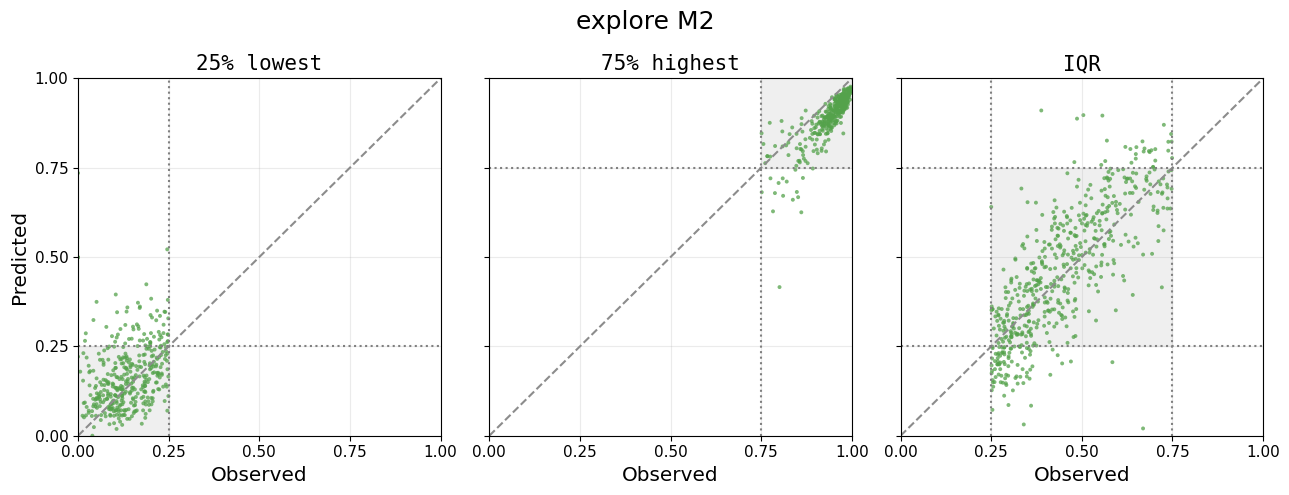

In [39]:
# select measurements with extreme low/high frac vals
# check how the predictions look like with ~ time + rmssd model
iqr_lo=.25
iqr_hi=.75
color_l='0.5'

fig,ax=plt.subplots(ncols=3, figsize=(13,5), sharex=True, sharey=True)

m_low=win['frac'] < iqr_lo
m_high=win['frac'] > iqr_hi
m_iqr=win['frac'].between(iqr_lo, iqr_hi)

x_low = win['frac'][m_low]
x_high = win['frac'][m_high]
x_iqr = win['frac'][m_iqr]

y_low = m1.predict()[m_low.values]
y_high = m1.predict()[m_high.values]
y_iqr = m1.predict()[m_iqr.values]

specs = [
    (ax[0], x_low, y_low, f'{100*iqr_lo:.0f}% lowest'),
    (ax[1], x_high, y_high, f'{100*iqr_hi:.0f}% highest'),
    (ax[2], x_iqr, y_iqr, 'IQR'),
]

for a, x, y, title in specs:
    a.scatter(x, y, s=8, alpha=0.75, color='#54a24b', edgecolor='none')
    a.axline((0,0), slope=1, color='0.55', lw=1.5, ls='--')
    a.set_title(title, fontsize=15, fontfamily='monospace')
    a.set_xticks([0, 0.25, 0.5, 0.75, 1])
    a.set_yticks([0, 0.25, 0.5, 0.75, 1])
    a.tick_params(axis='both', labelsize=11)
    a.grid(alpha=0.25)
    a.set_xlim((0,1))
    a.set_ylim((0,1))

ax[0].axhspan(0, iqr_lo, 0, iqr_lo, color='0.85', alpha=0.4, zorder=0)
ax[0].axhline(.25, color=color_l, ls=':', lw=1.5)
ax[0].axvline(.25, color=color_l, ls=':', lw=1.5)

ax[1].axhspan(iqr_hi, 1, iqr_hi, 1, color='0.85', alpha=0.4, zorder=0)
ax[1].axhline(.75, color=color_l, ls=':', lw=1.5)
ax[1].axvline(.75, color=color_l, ls=':', lw=1.5)

ax[2].axhspan(.25, .75, .25, .75, color='0.85', alpha=0.4, zorder=0)
ax[2].axhline(.25, color=color_l, ls=':', lw=1.5)
ax[2].axhline(.75, color=color_l, ls=':', lw=1.5)
ax[2].axvline(.25, color=color_l, ls=':', lw=1.5)
ax[2].axvline(.75, color=color_l, ls=':', lw=1.5)

ax[0].set_xlabel("Observed", fontsize='x-large')
ax[1].set_xlabel("Observed", fontsize='x-large')
ax[2].set_xlabel("Observed", fontsize='x-large')
ax[0].set_ylabel("Predicted", fontsize='x-large')

fig.suptitle('explore M2', fontsize=18, y=0.98)
fig.subplots_adjust(wspace=0.25)
plt.tight_layout()


### WIP HRV

In [40]:
temp=df.loc[df['User Id']==2]
np.allclose(bpm_to_rr(rr_to_bpm(temp['BBI (ms)'])), temp['BBI (ms)'])

True

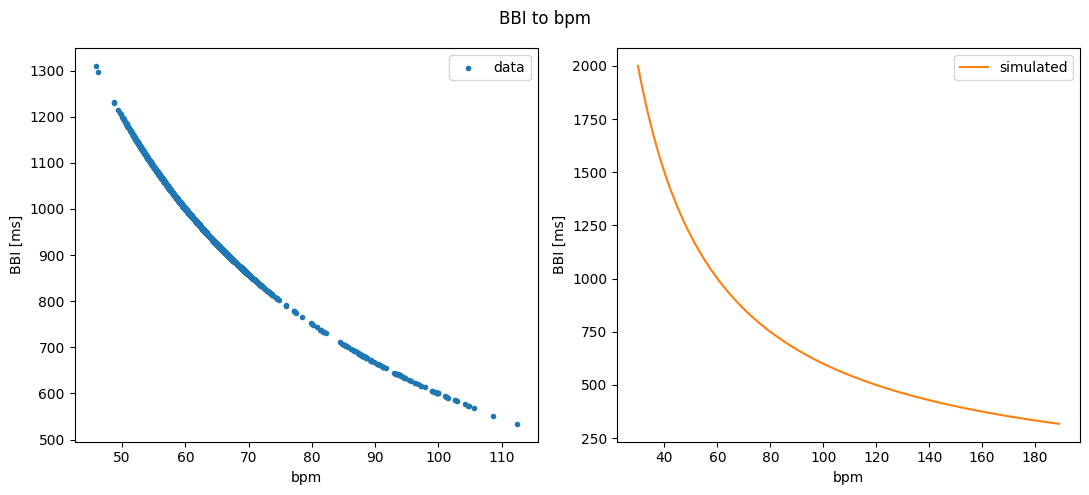

In [41]:
# bbi to bpm and back
fig,ax=plt.subplots(ncols=2, figsize=(11,5))

# data
x=rr_to_bpm(temp['BBI (ms)'].iloc[2434295:2436135])
y=temp['BBI (ms)'].iloc[2434295:2436135]

# simulate
x_sim=np.arange(30, 190)
y_sim=bpm_to_rr(x_sim)

ax[0].scatter(x,y, label='data', c='tab:blue', marker='.')
ax[1].plot(x_sim,y_sim, label='simulated', c='tab:orange')
for a in ax:
    a.set_xlabel('bpm')
    a.set_ylabel('BBI [ms]')
    a.legend()
fig.suptitle('BBI to bpm')
fig.tight_layout()

In [42]:
# High confidence
get_contigs_idx(temp.Status.map({'HIGH_CONFIDENCE':1, 'LOW_CONFIDENCE':0}), top_n=1, get_high=True)

(array([2434295], dtype=uint32),
 array([2436135], dtype=uint32),
 array([1840], dtype=uint32))

In [43]:
# check if there are any artefacts in 
artefacts=rr_artefacts(temp['BBI (ms)'].iloc[2434295:2436135], input_type='rr_ms')

for k in ['ectopic','long','short','missed','extra']:
    oopsie=artefacts.get(k)
    print(f'{sum(oopsie)} {k} found')
print(f'in total there are {len(oopsie)} BBIs')

50 ectopic found
11 long found
79 short found
1 missed found
0 extra found
in total there are 1840 BBIs


In [44]:
# Low confidence
get_contigs_idx(temp.Status.map({'HIGH_CONFIDENCE':1, 'LOW_CONFIDENCE':0}), top_n=1, get_high=False)

(array([2915577], dtype=uint32),
 array([2921646], dtype=uint32),
 array([6069], dtype=uint32))

In [45]:
# check if there are any artefacts in bad
artefacts_bad=rr_artefacts(temp['BBI (ms)'].iloc[2915577:2921646], input_type='rr_ms')

for k in ['ectopic','long','short','missed','extra']:
    oopsie=artefacts_bad.get(k)
    print(f'{sum(oopsie)} {k} found')
print(f'in total there are {len(oopsie)} BBIs')

98 ectopic found
2 long found
1 short found
99 missed found
9 extra found
in total there are 6069 BBIs


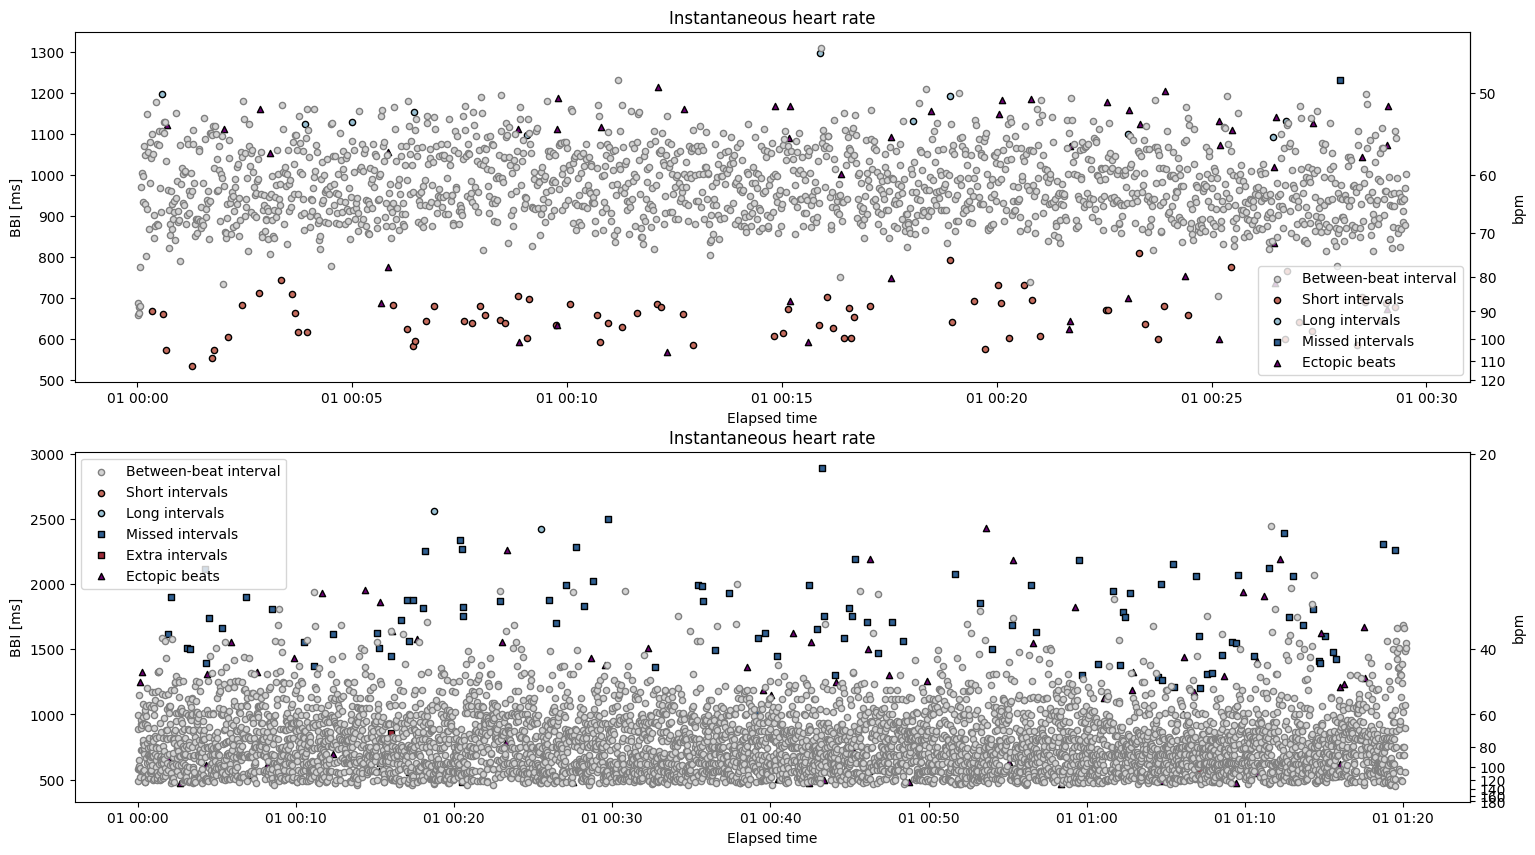

In [46]:
# plot interbeat intervals of high vs low confidence vals
fig, ax=plt.subplots(nrows=2, figsize=(18,10))

# good 
ax[0].set_title('High confidence BBIs')
plot_rr(temp['BBI (ms)'].iloc[2434295:2436135], input_type='rr_ms', unit='rr', show_artefacts=True, line=False, ax=ax[0]) # dont set unit to bpm


# bad 
ax[1].set_title('Low confidence BBIs')
a=df[df['User Id']==0]['Status'].map({'LOW_CONFIDENCE':0, 'HIGH_CONFIDENCE':1})
start,end,lens = get_contigs_idx(ar_input=a, top_n=1, get_high=False)
temp_bad = df.iloc[start[0]:end[0], :] # extend iloc index +-1 for sanity echecking
plot_rr(temp['BBI (ms)'].iloc[2915577:2921646], input_type='rr_ms', unit='rr', show_artefacts=True, line=False, ax=ax[1])

for a in ax:
    a.set_xlabel('Elapsed time')
    a.set_ylabel('BBI [ms]')

    ax_right=a.secondary_yaxis('right', functions=(rr_to_bpm, bpm_to_rr))
    ax_right.set_ylabel('bpm')
    
    _,labels=a.get_legend_handles_labels()
    a.legend(_, ['Between-beat interval' if x.startswith('R-R') else x for x in labels])


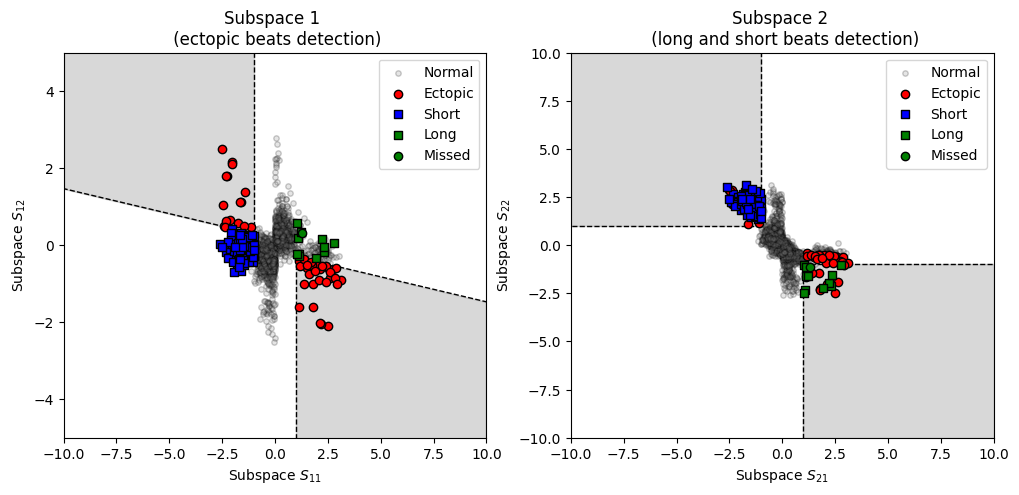

In [47]:
# good
_, ax = plt.subplots(ncols=2, figsize=(12, 5))
plot_subspaces(artefacts=artefacts, ax=ax)
plt.show()

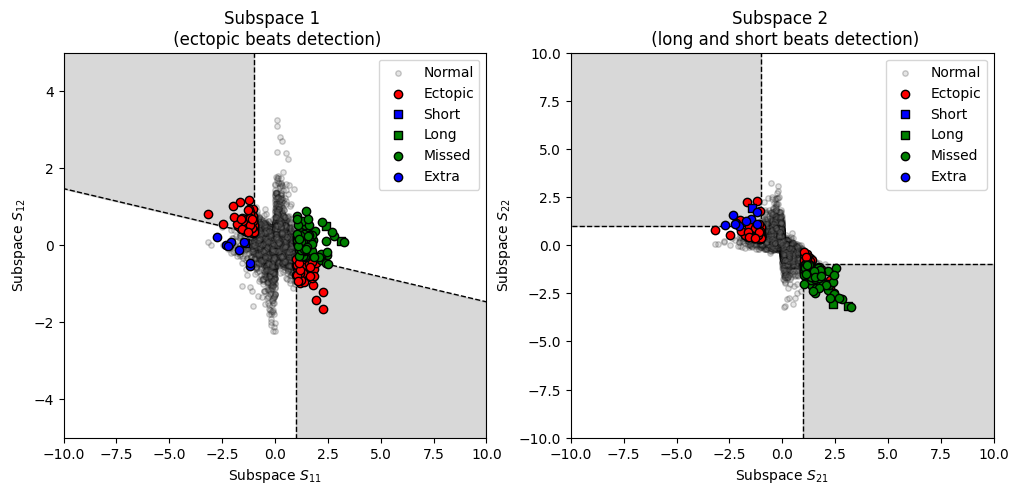

In [48]:
# bad
_, ax = plt.subplots(ncols=2, figsize=(12, 5))
plot_subspaces(artefacts=artefacts_bad, ax=ax)
plt.show()

##### i wanna see the dist of contigs per hour of day - during day very few long stretches of HIGH_CONFIDENCE

In [49]:
ar=df[df['User Id']==1]['Status'].map({'HIGH_CONFIDENCE':1, 'LOW_CONFIDENCE':0})

sta,sto,lens=get_contigs_idx(ar_input=ar,top_n=999999, get_high=True)

In [50]:
temp=df[df['User Id']==1]
m=np.where(lens>15)[0] # lets say it is enough to have at least 15 BBIs to estimate statistics

delta = np.zeros(len(temp) + 1, dtype=int)

np.add.at(delta, sta, 1)
np.add.at(delta, sto, -1)

#mask = np.cumsum(delta[:-1]) > 0
#selected = df.iloc[mask]